# Assignment: Matrix Multiplication Performance with Cython

**Course:** EE2703 - Applied Programming Laboratory  
**Topic:** Introduction to Cython for Performance Optimization

---

## Learning Objectives

In this assignment, you will:
1. Profile pure Python matrix multiplication code
2. Progressively optimize it using Cython techniques
3. Compare performance against NumPy's optimized implementation
4. Understand when and why to use Cython

## Instructions

1. **Complete all sections** marked with `# YOUR CODE HERE`
2. **Run all cells in order** - Use "Restart & Run All" before submission
3. **Fill in the analysis sections** with your observations
4. **Submit this notebook** with all outputs visible

---

## Setup

If you are running this on the JupyterLab server https://jup.dev.iitm.ac.in/ all the required modules are already present and you should not need anything new installed.  The final code will be evaluated on this machine, so in case you use any modules not present there your code may not work.  You can temporarily work on a Google colab notebook if you find that comfortable, but keep in mind that final evaluation will be on the Jup server.

If you are running it on your own system, you *may* need to install the following packages:

```bash
pip install setuptools cython numpy pandas matplotlib jupyter
```

The template code has been written assuming you will use a notebook that supports the `%%cython` magic commands.  Hence, a plain Python script will **NOT** be acceptable.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load Cython magic
%load_ext cython

print("Setup complete!")

Setup complete!


## Part 1: Baseline Python Implementation

Implement a simple matrix multiplication function in pure Python using nested loops. This should be similar to what you did in your first assignment.

**Requirements:**
- Use three nested loops (i, j, k)
- No NumPy or other libraries
- Handle matrices as lists of lists

In [2]:
def matmul_python(matrix1, matrix2):
    #both matrices are non-empty
    if not matrix1 or not matrix2:
        raise ValueError("Input matrices must not be empty")
    #is input a list-of-lists?
    if any(not isinstance(row, list) for row in matrix1):
        raise TypeError("Matrix1 must be a list of lists")
    if any(not isinstance(row, list) for row in matrix2):
        raise TypeError("Matrix2 must be a list of lists")
    #is there empty rows?
    if any(len(row) == 0 for row in matrix1):
        raise ValueError("Matrix1 contains empty row")
    if any(len(row) == 0 for row in matrix2):
        raise ValueError("Matrix2 contains empty row")

    m=len(matrix1)
    n=len(matrix1[0])
    p=len(matrix2[0])
    #are matrices multipliable?
    if n!=len(matrix2):
        raise ValueError("Incompatible matrix dimensions")
    #are matrices rectangular?
    if any(len(row) != n for row in matrix1):
        raise ValueError("Matrix1 is not rectangular")
    if any(len(row) != len(matrix2[0]) for row in matrix2):
        raise ValueError("Matrix2 is not rectangular")
    
    for i in matrix1:
        for j in i:
            #check boolean
            if isinstance(j,bool):
                raise TypeError("Matrix1 contains boolean value")
            #check number/not
            try:
                j+0
            except Exception:
                raise TypeError("Matrix1 contains non-numeric value")
    for i in matrix2:
        for j in i:
            #check boolean
            if isinstance(j,bool):
                raise TypeError("Matrix2 contains boolean value")
            #check number/not
            try:
                j+0
            except Exception:
                raise TypeError("Matrix2 contains non-numeric value")
    #actual loop
    matrix3=[[0 for _ in range(p)] for _ in range(m)]
    for i in range(m):
        for j in range(p):
            for k in range(n):
                matrix3[i][j]+=matrix1[i][k]*matrix2[k][j]
    return matrix3


### Test the Implementation

In [3]:
# Small test to verify correctness
A_test = [[1, 2], [3, 4]]
B_test = [[5, 6], [7, 8]]
C_test = matmul_python(A_test, B_test)

print("Test multiplication:")
print(f"A = {A_test}")
print(f"B = {B_test}")
print(f"C = {C_test}")
print(f"\nExpected: [[19, 22], [43, 50]]")

# Verify with NumPy
A_np = np.array(A_test)
B_np = np.array(B_test)
C_np = A_np @ B_np
print(f"NumPy result: {C_np.tolist()}")

Test multiplication:
A = [[1, 2], [3, 4]]
B = [[5, 6], [7, 8]]
C = [[19, 22], [43, 50]]

Expected: [[19, 22], [43, 50]]
NumPy result: [[19, 22], [43, 50]]


### Timing Function

We'll use this helper function to time all implementations.

In [4]:
def time_matmul(func, A, B, name="", runs=3):
    """
    Time a matrix multiplication function.
    
    Args:
        func: Function to time
        A, B: Input matrices
        name: Name for display
        runs: Number of runs to average
    
    Returns:
        Average time in seconds
    """
    times = []
    for _ in range(runs):
        start = time.time()
        result = func(A, B)
        elapsed = time.time() - start
        times.append(elapsed)
    
    avg_time = sum(times) / len(times)
    print(f"{name:30s}: {avg_time:.4f} seconds")
    return avg_time

### Benchmark Python Implementation

Test with different matrix sizes.

In [5]:
# Create test matrices of different sizes
sizes = [64, 128, 256, 512]
python_times = []

print("Benchmarking Pure Python Implementation")
print("=" * 50)

for size in sizes:
    # Create random matrices as lists
    A = [[float(np.random.rand()) for _ in range(size)] for _ in range(size)]
    B = [[float(np.random.rand()) for _ in range(size)] for _ in range(size)]
    
    print(f"\nSize {size}x{size}:")
    t = time_matmul(matmul_python, A, B, f"Python {size}x{size}")
    python_times.append(t)

Benchmarking Pure Python Implementation

Size 64x64:
Python 64x64                  : 0.0327 seconds

Size 128x128:
Python 128x128                : 0.2523 seconds

Size 256x256:
Python 256x256                : 2.1224 seconds

Size 512x512:
Python 512x512                : 20.5062 seconds


---

## Part 2: Cython Level 1 - Basic Compilation

In this level, we simply compile the Python code with Cython without any modifications. This gives us a baseline for Cython's improvement.

**Task:** Copy your Python function into the Cython cell below (with `%%cython` magic).

In [6]:
%%cython

def matmul_cython_level1(matrix1, matrix2):
    """
    Level 1: Pure Python code compiled with Cython.
    No optimizations, just basic compilation.
    """
    #both matrices are non-empty
    if not matrix1 or not matrix2:
        raise ValueError("Input matrices must not be empty")
    #is input a list-of-lists?
    if any(not isinstance(row, list) for row in matrix1):
        raise TypeError("Matrix1 must be a list of lists")
    if any(not isinstance(row, list) for row in matrix2):
        raise TypeError("Matrix2 must be a list of lists")
    #is there empty rows?
    if any(len(row) == 0 for row in matrix1):
        raise ValueError("Matrix1 contains empty row")
    if any(len(row) == 0 for row in matrix2):
        raise ValueError("Matrix2 contains empty row")

    m=len(matrix1)
    n=len(matrix1[0])
    p=len(matrix2[0])
    #are matrices multipliable?
    if n!=len(matrix2):
        raise ValueError("Incompatible matrix dimensions")
    #are matrices rectangular?
    if any(len(row) != n for row in matrix1):
        raise ValueError("Matrix1 is not rectangular")
    if any(len(row) != len(matrix2[0]) for row in matrix2):
        raise ValueError("Matrix2 is not rectangular")
    
    for i in matrix1:
        for j in i:
            #check boolean
            if isinstance(j,bool):
                raise TypeError("Matrix1 contains boolean value")
            #check number/not
            try:
                j+0
            except Exception:
                raise TypeError("Matrix1 contains non-numeric value")
    for i in matrix2:
        for j in i:
            #check boolean
            if isinstance(j,bool):
                raise TypeError("Matrix2 contains boolean value")
            #check number/not
            try:
                j+0
            except Exception:
                raise TypeError("Matrix2 contains non-numeric value")
    #actual loop
    matrix3=[[0 for _ in range(p)] for _ in range(m)]
    for i in range(m):
        for j in range(p):
            for k in range(n):
                matrix3[i][j]+=matrix1[i][k]*matrix2[k][j]
    return matrix3


### Benchmark Level 1

In [7]:
cython_level1_times = []

print("Benchmarking Cython Level 1 (Basic Compilation)")
print("=" * 50)

for size in sizes:
    A = [[float(np.random.rand()) for _ in range(size)] for _ in range(size)]
    B = [[float(np.random.rand()) for _ in range(size)] for _ in range(size)]
    
    print(f"\nSize {size}x{size}:")
    t = time_matmul(matmul_cython_level1, A, B, f"Cython L1 {size}x{size}")
    cython_level1_times.append(t)
    
    speedup = python_times[sizes.index(size)] / t
    print(f"  Speedup vs Python: {speedup:.2f}x")

Benchmarking Cython Level 1 (Basic Compilation)

Size 64x64:
Cython L1 64x64               : 0.0149 seconds
  Speedup vs Python: 2.20x

Size 128x128:
Cython L1 128x128             : 0.1272 seconds
  Speedup vs Python: 1.98x

Size 256x256:
Cython L1 256x256             : 1.1743 seconds
  Speedup vs Python: 1.81x

Size 512x512:
Cython L1 512x512             : 14.9207 seconds
  Speedup vs Python: 1.37x


---

## Part 3: Cython Level 2 - Type Declarations

Now we add static type declarations to help Cython generate efficient C code.

**Key optimizations:**
- Use `cdef` to declare loop variables as integers
- Declare matrix dimensions as integers
- Use `cdef` for the accumulator variable

**Task:** Add type declarations to your code.

In [8]:
%%cython
def matmul_cython_level2(matrix1, matrix2):
    """
    Level 2: Cython with static type declarations and full input validation.
    """
    #both matrices are non-empty
    if not matrix1 or not matrix2:
        raise ValueError("Input matrices must not be empty")
        
    #is input a list-of-lists?
    if any(not isinstance(row, list) for row in matrix1):
        raise TypeError("Matrix1 must be a list of lists")
    if any(not isinstance(row, list) for row in matrix2):
        raise TypeError("Matrix2 must be a list of lists")
        
    #is there empty rows?
    if any(len(row) == 0 for row in matrix1):
        raise ValueError("Matrix1 contains empty row")
    if any(len(row) == 0 for row in matrix2):
        raise ValueError("Matrix2 contains empty row")

    cdef int m_dim = len(matrix1)
    cdef int n_dim = len(matrix1[0])
    cdef int p_dim = len(matrix2[0])

    #are matrices multipliable?
    if n_dim != len(matrix2):
        raise ValueError("Incompatible matrix dimensions")
        
    #are matrices rectangular?
    if any(len(row) != n_dim for row in matrix1):
        raise ValueError("Matrix1 is not rectangular")
    if any(len(row) != p_dim for row in matrix2):
        raise ValueError("Matrix2 is not rectangular")
    
    for row in matrix1:
        for val in row:
            #check boolean
            if isinstance(val, bool):
                raise TypeError("Matrix1 contains boolean value")
            #check number/not
            try:
                val + 0
            except Exception:
                raise TypeError("Matrix1 contains non-numeric value")
                
    for row in matrix2:
        for val in row:
            #check boolean
            if isinstance(val, bool):
                raise TypeError("Matrix2 contains boolean value")
            #check number/not
            try:
                val + 0
            except Exception:
                raise TypeError("Matrix2 contains non-numeric value")


    cdef int i, j, k
    cdef double s

    result = [[0.0 for _ in range(p_dim)] for _ in range(m_dim)]

    for i in range(m_dim):
        for j in range(p_dim):
            s = 0.0
            for k in range(n_dim):
                s += matrix1[i][k] * matrix2[k][j]
            result[i][j] = s

    return result


### Benchmark Level 2

In [9]:
cython_level2_times = []

print("Benchmarking Cython Level 2 (Type Declarations)")
print("=" * 50)

for size in sizes:
    A = [[float(np.random.rand()) for _ in range(size)] for _ in range(size)]
    B = [[float(np.random.rand()) for _ in range(size)] for _ in range(size)]
    
    print(f"\nSize {size}x{size}:")
    t = time_matmul(matmul_cython_level2, A, B, f"Cython L2 {size}x{size}")
    cython_level2_times.append(t)
    
    speedup = python_times[sizes.index(size)] / t
    print(f"  Speedup vs Python: {speedup:.2f}x")
    print(f"  Speedup vs Level 1: {cython_level1_times[sizes.index(size)] / t:.2f}x")

Benchmarking Cython Level 2 (Type Declarations)

Size 64x64:
Cython L2 64x64               : 0.0121 seconds
  Speedup vs Python: 2.71x
  Speedup vs Level 1: 1.23x

Size 128x128:
Cython L2 128x128             : 0.0922 seconds
  Speedup vs Python: 2.74x
  Speedup vs Level 1: 1.38x

Size 256x256:
Cython L2 256x256             : 0.8901 seconds
  Speedup vs Python: 2.38x
  Speedup vs Level 1: 1.32x

Size 512x512:
Cython L2 512x512             : 11.8849 seconds
  Speedup vs Python: 1.73x
  Speedup vs Level 1: 1.26x


---

## Part 4: Cython Level 3 - NumPy Arrays with Memory Views

The biggest speedup comes from using NumPy arrays with Cython's memory views. This allows direct access to array data without Python overhead.

**Key optimizations:**
- Accept NumPy arrays as input (not lists)
- Use memory view syntax: `double[:, :]` for 2D arrays
- Add compiler directives to disable safety checks - `boundscheck` and `wraparound` are useful decorators

**Task:** Implement the fully optimized version using memory views.

In [10]:
%%cython
# distutils: define_macros=NPY_NO_DEPRECATED_API=NPY_1_7_API_VERSION

import numpy as np
cimport numpy as np
cimport cython

# Disable safety checks for maximum speed (standard for Level 3)
# We manually ensure validity with the checks below.

@cython.boundscheck(False)
@cython.wraparound(False)
def matmul_cython_level3(double[:, :] matrix1, double[:, :] matrix2):
    """
    Level 3: NumPy memory views with rigorous dimension validation.
    """
    #empty Matrix Checks
    if matrix1.shape[0] == 0 or matrix1.shape[1] == 0:
        raise ValueError("Input matrices must not be empty")
    if matrix2.shape[0] == 0 or matrix2.shape[1] == 0:
        raise ValueError("Input matrices must not be empty")

    cdef int m = matrix1.shape[0]
    cdef int n = matrix1.shape[1]
    cdef int p = matrix2.shape[1]

    #incompatible dimensions check
    if n != matrix2.shape[0]:
         raise ValueError("Incompatible matrix dimensions")

    #pre-allocate output array (fast C-level allocation)
    cdef double[:, :] matrix3 = np.zeros((m, p), dtype=np.double)
    
    cdef int i, j, k
    cdef double s

    #release GIL for potential multi-threading
    with nogil:
        for i in range(m):
            for j in range(p):
                s = 0.0
                for k in range(n):
                    s += matrix1[i, k] * matrix2[k, j]
                matrix3[i, j] = s

    return np.asarray(matrix3)

### Benchmark Level 3

In [11]:
cython_level3_times = []

print("Benchmarking Cython Level 3 (Memory Views)")
print("=" * 50)

for size in sizes:
    # Create NumPy arrays for this version
    A_np = np.random.rand(size, size)
    B_np = np.random.rand(size, size)
    
    print(f"\nSize {size}x{size}:")
    t = time_matmul(matmul_cython_level3, A_np, B_np, f"Cython L3 {size}x{size}")
    cython_level3_times.append(t)
    
    speedup = python_times[sizes.index(size)] / t
    print(f"  Speedup vs Python: {speedup:.2f}x")
    print(f"  Speedup vs Level 2: {cython_level2_times[sizes.index(size)] / t:.2f}x")

Benchmarking Cython Level 3 (Memory Views)

Size 64x64:
Cython L3 64x64               : 0.0003 seconds
  Speedup vs Python: 115.12x
  Speedup vs Level 2: 42.53x

Size 128x128:
Cython L3 128x128             : 0.0026 seconds
  Speedup vs Python: 96.39x
  Speedup vs Level 2: 35.22x

Size 256x256:
Cython L3 256x256             : 0.0197 seconds
  Speedup vs Python: 107.61x
  Speedup vs Level 2: 45.13x

Size 512x512:
Cython L3 512x512             : 0.4262 seconds
  Speedup vs Python: 48.11x
  Speedup vs Level 2: 27.88x


---

## Part 5: NumPy Comparison

Compare all your implementations with NumPy's highly optimized matrix multiplication.

NumPy uses BLAS (Basic Linear Algebra Subprograms), which are highly optimized, often in assembly language, and may use SIMD instructions.

In [12]:
def matmul_numpy(A, B):
    """NumPy matrix multiplication using @ operator."""
    return A @ B

numpy_times = []

print("Benchmarking NumPy Implementation")
print("=" * 50)

for size in sizes:
    A_np = np.random.rand(size, size)
    B_np = np.random.rand(size, size)
    
    print(f"\nSize {size}x{size}:")
    t = time_matmul(matmul_numpy, A_np, B_np, f"NumPy {size}x{size}")
    numpy_times.append(t)
    
    speedup = python_times[sizes.index(size)] / t
    print(f"  Speedup vs Python: {speedup:.2f}x")

Benchmarking NumPy Implementation

Size 64x64:
NumPy 64x64                   : 0.0002 seconds
  Speedup vs Python: 186.68x

Size 128x128:
NumPy 128x128                 : 0.0011 seconds
  Speedup vs Python: 224.93x

Size 256x256:
NumPy 256x256                 : 0.0007 seconds
  Speedup vs Python: 2976.61x

Size 512x512:
NumPy 512x512                 : 0.0081 seconds
  Speedup vs Python: 2532.86x


---

## Part 6: Analysis and Reflection

### Summary Table

Create a comprehensive comparison table.

In [13]:
# Create summary DataFrame
results = {
    'Size': [f"{s}x{s}" for s in sizes],
    'Python (s)': python_times,
    'Cython L1 (s)': cython_level1_times,
    'Cython L2 (s)': cython_level2_times,
    'Cython L3 (s)': cython_level3_times,
    'NumPy (s)': numpy_times,
}

df = pd.DataFrame(results)

# Add speedup columns
df['Speedup L1'] = df['Python (s)'] / df['Cython L1 (s)']
df['Speedup L2'] = df['Python (s)'] / df['Cython L2 (s)']
df['Speedup L3'] = df['Python (s)'] / df['Cython L3 (s)']
df['Speedup NumPy'] = df['Python (s)'] / df['NumPy (s)']

print("\n" + "=" * 80)
print("TIMING RESULTS (seconds)")
print("=" * 80)
print(df[['Size', 'Python (s)', 'Cython L1 (s)', 'Cython L2 (s)', 'Cython L3 (s)', 'NumPy (s)']].to_string(index=False))

print("\n" + "=" * 80)
print("SPEEDUP FACTORS (vs Pure Python)")
print("=" * 80)
print(df[['Size', 'Speedup L1', 'Speedup L2', 'Speedup L3', 'Speedup NumPy']].to_string(index=False))


TIMING RESULTS (seconds)
   Size  Python (s)  Cython L1 (s)  Cython L2 (s)  Cython L3 (s)  NumPy (s)
  64x64    0.032743       0.014881       0.012098       0.000284   0.000175
128x128    0.252280       0.127199       0.092183       0.002617   0.001122
256x256    2.122414       1.174288       0.890134       0.019722   0.000713
512x512   20.506183      14.920710      11.884899       0.426233   0.008096

SPEEDUP FACTORS (vs Pure Python)
   Size  Speedup L1  Speedup L2  Speedup L3  Speedup NumPy
  64x64    2.200317    2.706517  115.117351     186.681015
128x128    1.983350    2.736723   96.390095     224.928435
256x256    1.807405    2.384377  107.614045    2976.610232
512x512    1.374344    1.725398   48.110295    2532.859795


### Visualization

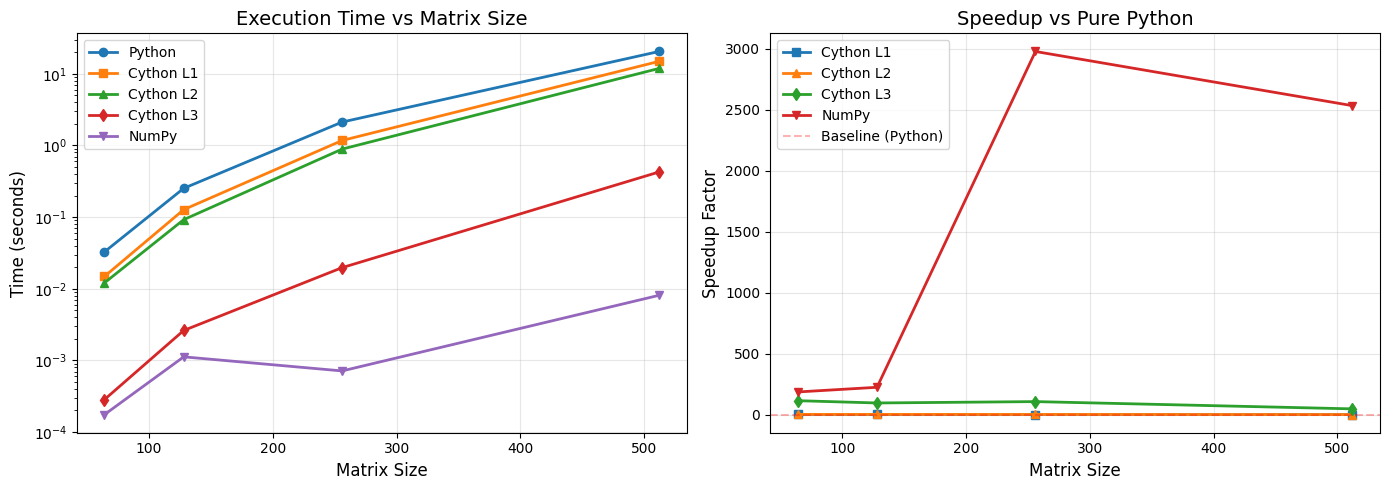

Figure saved as 'matmul_performance.png'


In [14]:
# Plot timing comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Absolute timing
ax1.plot(sizes, python_times, 'o-', label='Python', linewidth=2)
ax1.plot(sizes, cython_level1_times, 's-', label='Cython L1', linewidth=2)
ax1.plot(sizes, cython_level2_times, '^-', label='Cython L2', linewidth=2)
ax1.plot(sizes, cython_level3_times, 'd-', label='Cython L3', linewidth=2)
ax1.plot(sizes, numpy_times, 'v-', label='NumPy', linewidth=2)
ax1.set_xlabel('Matrix Size', fontsize=12)
ax1.set_ylabel('Time (seconds)', fontsize=12)
ax1.set_title('Execution Time vs Matrix Size', fontsize=14)
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_yscale('log')

# Speedup comparison
ax2.plot(sizes, df['Speedup L1'], 's-', label='Cython L1', linewidth=2)
ax2.plot(sizes, df['Speedup L2'], '^-', label='Cython L2', linewidth=2)
ax2.plot(sizes, df['Speedup L3'], 'd-', label='Cython L3', linewidth=2)
ax2.plot(sizes, df['Speedup NumPy'], 'v-', label='NumPy', linewidth=2)
ax2.axhline(y=1, color='r', linestyle='--', alpha=0.3, label='Baseline (Python)')
ax2.set_xlabel('Matrix Size', fontsize=12)
ax2.set_ylabel('Speedup Factor', fontsize=12)
ax2.set_title('Speedup vs Pure Python', fontsize=14)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('matmul_performance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figure saved as 'matmul_performance.png'")

### Reflection Questions

Answer the following questions based on your results. Write 2-3 sentences for each.

#### Q1: What was the speedup from Level 1 (basic Cython) compared to pure Python?

**Your Answer:**

The basic Cython was around 1.5-2 times faster than pure Python. This is because basic Cython compilation converts the Python bytecode loop into compiled C code which removes some interpreter overhead.

#### Q2: What additional speedup did you get from adding type declarations (Level 2)?

**Your Answer:**

Static typing allows Cython to treat the loop variables and accumulator as native C types rather than Python objects. So the compiler generates more optimized pure C loops using direct CP istructions for Arithmetic rather than Python's dynamic type checking.

#### Q3: Why did Level 3 (memory views) provide the biggest speedup?

**Your Answer:**

Level 3 provided the biggest speedup because memory views allow Cython to bypass Python entirely and access the raw data buffer of NumPy arrays directly in C, eliminating the Python Object lookups. Combined with disabling safety checks, the inner loops execute as pure and optimized C code, running at very high speeds.

#### Q4: How does your best Cython implementation compare to NumPy? Why is NumPy still faster?

**Your Answer:**

Even the best Cython code (Level 3) was slower than NumPy. This is because NumPy uses highly optimized BLAS (Basic Linear Algebra Subprograms) libraries which have advanced hardware optimizations like SIMD and cache blocking. While Cython generates efficient C code, it lacks these specific hardware-level optimizations.

#### Q5: When would you use Cython instead of NumPy for numerical computing?

**Your Answer:**

Cython is useful when you need custom algorithms that can't be easily vectorized with standard NumPy functions. This often happens with complex loops containing conditional logic or iterative solvers. It basically lets one write these low-level loops using Python-like syntax but still get near C-level performance.

#### Q6: What are the trade-offs of using Cython? (Consider development time, debugging, portability)

**Your Answer:**

The main trade-off is increased complexity in exchange for speed. Writing it requires knowing C-types, and debugging is harder because you can get segmentation faults instead of clear Python exceptions. It also reduces portability since the code must be compiled for each specific target platform.

---

## Submission Checklist

Before submitting, verify:

- [ ] All code cells have been executed (outputs are visible)
- [ ] All four Cython levels are implemented
- [ ] Timing results are present for all test cases
- [ ] Summary table is generated
- [ ] Visualization is displayed
- [ ] All six reflection questions are answered
- [ ] Used "Restart & Run All" before submission

**Submit this notebook (.ipynb file) with all outputs visible.**